# Five qubits + four tunable couplers: first pass

**To change the design:** edit the numbers in the *Design parameters* cell, then **Restart & Run All**.

The cells after that build the chip from those numbers. The only hand-placed layout coordinates are in the control-line routing table, and its comments say so.

Two custom components live next to this notebook: the tunable coupler in `h_coupler.py` and the floating flux line in `floating_flux.py`. `capacitance.py` estimates the island capacitances that the junction sizes are computed from.

Readout is in reflection through launchpad N1. The shared feedline is itself the Purcell filter, a quarter-wave resonator at the readout band.

In [41]:
import math
import os

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

from qiskit_metal import designs, Dict
import qiskit_metal as qm
from qiskit_metal.qlibrary.qubits.transmon_cross_fl import TransmonCrossFL
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.terminations.short_to_ground import ShortToGround
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.anchored_path import RouteAnchors

from qiskit_metal.qlibrary.couplers.line_tee import LineTee

from h_coupler import TransmonHCoupler  # local file: h_coupler.py
from floating_flux import FloatingFluxLine  # local file: floating_flux.py

## Design parameters

In [42]:
# =====================================================================
#  DESIGN PARAMETERS
#  Every number you are likely to tune lives in this cell. Edit, then
#  Restart & Run All. The suffix on each name is its unit (_um / _mm).
# =====================================================================

# --- Chip ------------------------------------------------------------
chip_size_mm = 5.0
cpw_width_um = 10  # default centre trace for every route
cpw_gap_um = 6

# --- Qubits (TransmonCrossFL) -----------------------------------------
n_qubits = 5
qubit_pitch_mm = 0.75
qubit_row_y_mm = 0.0
cross_width_um = 30  # metal arm width
# Etched pocket around the cross, per arm: the length is measured from the
# edge of the central square to the arm's etched tip, the width across it.
# The metal arm length and the gap follow from these and cross_width_um.
cross_etch_arm_length_um = 215.45
cross_etch_arm_width_um = 89.1

# Readout claw on the north arm: a U of metal wrapped around the arm tip.
# Sizes are of the claw metal itself. "Length" runs along the arm,
# "width" across it. The ground spacing (claw gap to cross gap) follows
# from these and the cross sizes above.
claw_outer_length_um = 210.9
claw_outer_width_um = 128.9
claw_inner_length_um = 200
claw_inner_width_um = 107.1
claw_gap_um = 6

# XY drive pad (open-ended CPW). Inner qubits: placed beside the south arm,
# relative to the qubit centre. The two edge qubits are instead driven
# end-on through their outer arm (west for Q0, east for the last qubit),
# with this much ground between the arm's pocket tip and the line's open end.
edge_xy_pad_spacing_um = 30
xy_pad_dx_mm = -0.10
xy_pad_dy_mm = -0.18
xy_pad_width_um = 10
xy_pad_gap_um = 6
xy_pad_termination_gap_um = 6

# Flux-line T at the SQUID (used by the couplers and every qubit except the
# floating one below)
flux_t_top_um = 15
flux_t_width_um = 5
flux_t_gap_um = 3
flux_t_inductive_gap_um = 3
flux_t_offset_um = 0

# Floating flux line on the last qubit: a hairpin under the SQUID, wired
# between two launchpads, never touching ground. Trace, gap and inductive gap
# match the flux T above.
floating_flux_leg_pitch_um = 40  # centre-to-centre spacing of the two legs
floating_flux_leg_length_um = 30

# --- Tunable couplers (TransmonHCoupler, see h_coupler.py) ------------
# One I-beam coupler midway between each qubit pair, on the qubit row.
# The tip of each neighbouring qubit's etched arm pocket sits inside one of
# its slots, with a strip of ground plane all the way round between that
# pocket and the coupler's own etch.
coupler_insertion_um = 80  # how far the bars reach past each qubit pocket tip
coupler_ground_strip_um = 5  # ground between qubit pocket and coupler etch
coupler_bar_width_um = cross_width_um  # top and bottom bars, same as the Xmon arms
coupler_web_width_um = cross_width_um  # vertical web joining the bars
coupler_pocket_gap_um = 15  # coupler metal to ground plane
coupler_jj_width_um = 20

# --- Josephson junctions --------------------------------------------
# Every qubit and coupler has a symmetric SQUID: two identical Dolan-bridge
# junctions in parallel. Each junction is drawn like the reference cell: a
# 2 um lead tapering to a finger 1.36 um long that stops 0.15 um short of the
# other electrode. Only the finger width changes from element to element.
# Junction area = finger width x overlap. The overlap comes from the bridge
# height and evaporation angles, not the layout, so it is an input here.
jj_jc_ua_per_um2 = 0.5  # critical current density
jj_overlap_um = 0.20  # ASSUMED: put in your process's measured overlap
jj_reference_finger_width_um = 0.42  # the reference cell, for comparison
# Maximum (zero-flux) frequencies; flux tunes each element down from here.
qubit_freqs_ghz = [4.5, 4.8, 4.5, 4.8, 4.5]  # Q0..Q4, neighbours detuned
coupler_freqs_ghz = [6.0, 6.0, 6.0, 6.0]  # TC0..TC3
# Island capacitance to everything else (C_sigma), which sets E_C. From
# capacitance.py on this geometry (Q2 and TC1). After changing the cross, claw
# or coupler sizes, set run_capacitance_check = True and paste the new values.
qubit_csigma_ff = 120.4
coupler_csigma_ff = 151.7
run_capacitance_check = False  # a minute or two; runs in the last cell

# --- Readout --------------------------------------------------------------
# Target bare quarter-wave frequencies, Q0..Q4. The meander lengths are
# computed from these (see the resonator cell), so edit frequencies, not lengths.
resonator_freqs_ghz = [7.3, 7.4, 7.5, 7.6, 7.7]
substrate_eps_r = 11.45  # silicon at cryogenic temperature
resonator_meander_spacing_um = 50
resonator_lead_um = 150  # straight section at each end of the meander
resonator_fillet_um = 20

# Purcell filter: the shared feedline is itself a quarter-wave resonator at
# the readout band, so readout photons get out and the far-detuned qubits
# are blocked. Read out in reflection from N1. The line starts at its west
# end, where N1 drops onto it and a short stub runs to ground; the stub's
# length sets the filter Q (bandwidth = freq / Q). The line then runs east
# through every tee and ends open past the last one, folding up and back
# west only if it is too long to fit before purcell_fold_x_mm.
purcell_filter_freq_ghz = 7.5
purcell_filter_q = 15  # 500 MHz bandwidth, covering the readout band
feedline_y_mm = 1.5
purcell_short_x_mm = -1.80  # the short stub runs west to here, then up to ground
purcell_fold_x_mm = 1.70  # east end of the feedline turns north here...
purcell_fold_y_mm = 1.75  # ...and runs back west at this height to the open end
tee_coupling_length_um = 200
tee_coupling_space_um = 4

# --- Launchpads -------------------------------------------------------
pad_inset_mm = 2.2  # pad centre distance from chip centre
ns_pad_offsets_mm = [-1.625, -0.975, -0.325, 0.325, 0.975, 1.625]  # N & S edges
ew_pad_offsets_mm = [-1.6, -0.6, 0.4, 1.4]  # E & W edges

# --- Routing --------------------------------------------------------
control_line_fillet_um = 50
feedline_fillet_um = 50

## Josephson junctions

In [ ]:
# SQUID size for each element from its target frequency and C_sigma.
#   transmon:  f01 = sqrt(8 E_J E_C) - E_C, so E_J = (f + E_C)^2 / (8 E_C)
#   E_C/h = e^2 / (2 h C),  E_J/h = I_c Phi_0 / (2 pi h),  L_J = Phi_0 / (2 pi I_c)
# At zero flux a symmetric SQUID is one junction with the I_c of both halves.
EC_GHZ_FF = 19.37  # e^2 / 2h, in GHz * fF
EJ_GHZ_PER_UA = 496.7  # Phi_0 / (2 pi h), in GHz per uA
PHI0_2PI_NH_UA = 0.3291  # Phi_0 / 2 pi, in nH * uA


def squid_for(freq_ghz, csigma_ff):
    ec_ghz = EC_GHZ_FF / csigma_ff
    ej_ghz = (freq_ghz + ec_ghz) ** 2 / (8 * ec_ghz)
    ic_ua = ej_ghz / EJ_GHZ_PER_UA  # whole SQUID
    area_um2 = ic_ua / 2 / jj_jc_ua_per_um2  # each of its two junctions
    return dict(
        freq_ghz=freq_ghz,
        ec_mhz=ec_ghz * 1e3,
        ej_ghz=ej_ghz,
        ic_na=ic_ua * 1e3,
        lj_nh=PHI0_2PI_NH_UA / ic_ua,
        area_um2=area_um2,
        finger_um=area_um2 / jj_overlap_um,
    )


squids = {f"Q{i}": squid_for(f, qubit_csigma_ff) for i, f in enumerate(qubit_freqs_ghz)}
squids.update(
    {f"TC{i}": squid_for(f, coupler_csigma_ff) for i, f in enumerate(coupler_freqs_ghz)}
)

ref_area_um2 = jj_reference_finger_width_um * jj_overlap_um
print(
    f"Jc {jj_jc_ua_per_um2} uA/um^2, overlap {jj_overlap_um} um. Reference junction: "
    f"{ref_area_um2:.3f} um^2, Ic {ref_area_um2 * jj_jc_ua_per_um2 * 1e3:.0f} nA"
)
print("        f_max   E_C    E_J/E_C  SQUID Ic  L_J    per junction")
print("        (GHz)  (MHz)            (nA)     (nH)   area (um^2)  finger (um)")
for name, s in squids.items():
    print(
        f"  {name:<5} {s['freq_ghz']:5.2f} {s['ec_mhz']:6.0f} {s['ej_ghz'] / s['ec_mhz'] * 1e3:8.0f}"
        f" {s['ic_na']:9.1f} {s['lj_nh']:6.2f}   {s['area_um2']:.4f}       {s['finger_um']:.3f}"
    )
    if s["finger_um"] < 0.1:
        print(f"  WARNING: {name} needs a finger under 100 nm; raise C_sigma or the target.")


## Qubits and tunable couplers

In [43]:
design = designs.DesignPlanar()
design.chips.main.size.size_x = f"{chip_size_mm}mm"
design.chips.main.size.size_y = f"{chip_size_mm}mm"
design.variables.cpw_width = f"{cpw_width_um}um"
design.variables.cpw_gap = f"{cpw_gap_um}um"
design.overwrite_enabled = True

flux_t_options = dict(
    t_top=f"{flux_t_top_um}um",
    t_width=f"{flux_t_width_um}um",
    t_gap=f"{flux_t_gap_um}um",
    t_inductive_gap=f"{flux_t_inductive_gap_um}um",
    t_offset=f"{flux_t_offset_um}um",
)


# Cross gap and metal arm length (centre to tip), from the etch sizes.
cross_gap_um = (cross_etch_arm_width_um - cross_width_um) / 2
cross_length_um = cross_etch_arm_width_um / 2 + cross_etch_arm_length_um - cross_gap_um
pocket_tip_um = cross_length_um + cross_gap_um  # centre to etched arm tip

# Claw metal thicknesses and the ground spacing, from the outer/inner sizes.
claw_side_um = (claw_outer_width_um - claw_inner_width_um) / 2
claw_back_um = claw_outer_length_um - claw_inner_length_um
claw_ground_spacing_um = (
    claw_inner_width_um - cross_width_um - 2 * cross_gap_um
) / 2 - claw_gap_um
if claw_ground_spacing_um < 0:
    print(
        f"WARNING: claw inner width {claw_inner_width_um} um is too narrow for the "
        f"cross arm pocket ({cross_width_um} + 2 x {cross_gap_um} um) plus the claw gap. "
        f"Ground spacing = {claw_ground_spacing_um:.2f} um: the claw overlaps the pocket."
    )
# Distance from qubit centre to the claw finger tips, vs. the E/W arm pocket.
claw_tip_um = cross_length_um + cross_gap_um + claw_ground_spacing_um + claw_gap_um - claw_inner_length_um
if claw_tip_um - claw_gap_um < cross_width_um / 2 + cross_gap_um:
    print(
        f"WARNING: claw fingers reach {claw_tip_um:.1f} um from the qubit centre and "
        f"run into the E/W arm pocket (edge at {cross_width_um / 2 + cross_gap_um} um)."
    )


def qubit_x(i):
    """x position (mm) of qubit i, centred on the chip."""
    return (i - (n_qubits - 1) / 2) * qubit_pitch_mm


floating_flux_qubit = n_qubits - 1  # routed to two pads in the control-line table

qubits, xy_pads = [], []
for i in range(n_qubits):
    x_pos = qubit_x(i)
    floating = i == floating_flux_qubit
    qubits.append(
        TransmonCrossFL(
            design,
            f"Q{i}",
            options=dict(
                pos_x=f"{x_pos}mm",
                pos_y=f"{qubit_row_y_mm}mm",
                orientation="0",
                cross_width=f"{cross_width_um}um",
                cross_length=f"{cross_length_um}um",
                cross_gap=f"{cross_gap_um}um",
                make_fl=not floating,
                fl_options=flux_t_options,
                connection_pads=dict(
                    readout=dict(
                        connector_type="0",
                        claw_length=f"{claw_inner_length_um}um",
                        claw_width=f"{claw_side_um}um",
                        claw_width_back=f"{claw_back_um}um",
                        ground_spacing=f"{claw_ground_spacing_um}um",
                        claw_gap=f"{claw_gap_um}um",
                        connector_location="90",
                    )
                ),
            ),
        )
    )
    if floating:
        FloatingFluxLine(
            design,
            f"Q{i}_floating_flux",
            options=dict(
                pos_x=f"{x_pos}mm",
                pos_y=f"{qubit_row_y_mm - pocket_tip_um / 1e3}mm",  # under the SQUID
                width=f"{flux_t_width_um}um",
                gap=f"{flux_t_gap_um}um",
                inductive_gap=f"{flux_t_inductive_gap_um}um",
                leg_pitch=f"{floating_flux_leg_pitch_um}um",
                leg_length=f"{floating_flux_leg_length_um}um",
            ),
        )
    if i in (0, n_qubits - 1):
        # Edge qubit: open end faces the outer arm tip, line leaves sideways
        side = -1 if i == 0 else 1
        reach_um = pocket_tip_um + edge_xy_pad_spacing_um + xy_pad_termination_gap_um
        xy_x, xy_y = x_pos + side * reach_um / 1e3, qubit_row_y_mm
        xy_orient = "0" if i == 0 else "180"
    else:
        xy_x, xy_y = x_pos + xy_pad_dx_mm, qubit_row_y_mm + xy_pad_dy_mm
        xy_orient = "90"
    xy_pads.append(
        OpenToGround(
            design,
            f"XY_pad_{i}",
            options=dict(
                pos_x=f"{xy_x}mm",
                pos_y=f"{xy_y}mm",
                orientation=xy_orient,
                width=f"{xy_pad_width_um}um",
                gap=f"{xy_pad_gap_um}um",
                termination_gap=f"{xy_pad_termination_gap_um}um",
            ),
        )
    )

print(f"Design initialized on a {chip_size_mm} x {chip_size_mm} mm chip.")
print(f"Placed qubits Q0-Q{n_qubits - 1} and their XY coupling pads.")
print(f"  Q{floating_flux_qubit} has the floating flux line.")

03:23AM 20s INFO [_start_renderers]: Renderer=hfss skipped: runtime dependency not installed (QAnsysRenderer requires pyEPR. Install with: pip install 'quantum-metal[ansys]').
03:23AM 20s INFO [_start_renderers]: Renderer=q3d skipped: runtime dependency not installed (QAnsysRenderer requires pyEPR. Install with: pip install 'quantum-metal[ansys]').
03:23AM 20s INFO [_start_renderers]: Renderer=gmsh skipped: runtime dependency not installed (renderer_gmsh requires gmsh. Install with: pip install 'quantum-metal[mesh]' (or the legacy alias 'quantum-metal[fem]')).
03:23AM 20s INFO [_start_renderers]: Renderer=aedt_q3d skipped: runtime dependency not installed (QPyaedt requires pyaedt (ansys.aedt.core). Install with: pip install 'quantum-metal[ansys]').


03:23AM 20s INFO [_start_renderers]: Renderer=aedt_hfss skipped: runtime dependency not installed (QPyaedt requires pyaedt (ansys.aedt.core). Install with: pip install 'quantum-metal[ansys]').


Design initialized on a 5.0 x 5.0 mm chip.
Placed qubits Q0-Q4 and their XY coupling pads.
  Q4 has the floating flux line.


In [44]:
# Coupler geometry follows from the qubit pockets and the coupler knobs, so
# changing the qubit pitch or etch size keeps each pocket tip centred in its
# slot with at least the ground strip around it (more in front of the tip
# when the web is narrower than the room available).
pocket_tip_from_coupler_um = (
    qubit_pitch_mm * 1e3 / 2 - cross_etch_arm_width_um / 2 - cross_etch_arm_length_um
)
coupler_clearance_um = coupler_ground_strip_um + coupler_pocket_gap_um
coupler_bar_length_um = 2 * (pocket_tip_from_coupler_um + coupler_insertion_um)
coupler_slot_height_um = cross_etch_arm_width_um + 2 * coupler_clearance_um
# The web's etch must leave at least the ground strip before each pocket tip
web_room_um = 2 * (pocket_tip_from_coupler_um - coupler_clearance_um)
assert coupler_web_width_um <= web_room_um, (
    f"coupler_web_width_um = {coupler_web_width_um} um does not fit between the "
    f"neighbouring qubit pockets (room for {web_room_um:.0f} um): narrow the web, "
    "reduce coupler_ground_strip_um / coupler_pocket_gap_um, or widen qubit_pitch_mm."
)

tunable_couplers = []
for i in range(n_qubits - 1):
    tunable_couplers.append(
        TransmonHCoupler(
            design,
            f"TC{i}",
            options=dict(
                pos_x=f"{(qubit_x(i) + qubit_x(i + 1)) / 2}mm",
                pos_y=f"{qubit_row_y_mm}mm",
                orientation="0",
                bar_length=f"{coupler_bar_length_um}um",
                bar_width=f"{coupler_bar_width_um}um",
                slot_height=f"{coupler_slot_height_um}um",
                web_width=f"{coupler_web_width_um}um",
                pocket_gap=f"{coupler_pocket_gap_um}um",
                jj_width=f"{coupler_jj_width_um}um",
                make_fl=True,
                fl_options=flux_t_options,
            ),
        )
    )

print(f"Placed tunable couplers TC0-TC{n_qubits - 2} between the qubits.")
print(
    f"  coupler bars {coupler_bar_length_um:.0f} um long, web "
    f"{coupler_web_width_um:.0f} um, slot {coupler_slot_height_um:.0f} um tall"
)

Placed tunable couplers TC0-TC3 between the qubits.
  coupler bars 390 um long, web 30 um, slot 129 um tall


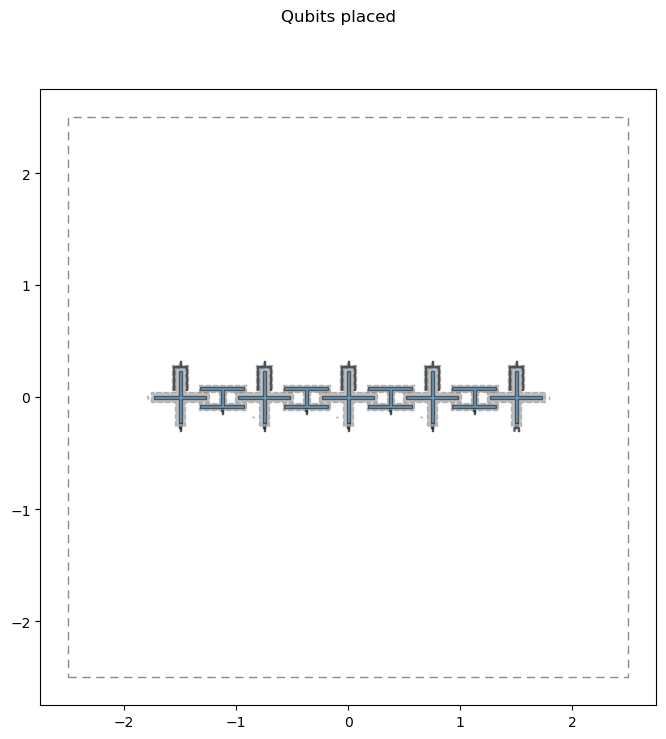

In [45]:
fig = qm.view(design)
fig.suptitle("Qubits placed")
fig

## Readout and feedline

In [46]:
# Each tee is shifted so its coupled-line end sits directly above the
# qubit's claw, keeping every resonator a straight vertical meander. Tees on
# the west half are mirrored (coupled end on their west side), which keeps
# the row of tees symmetric about the chip centre.
readout_tees = []
for i in range(n_qubits):
    mirror = i < (n_qubits - 1) / 2
    shift_mm = (1 if mirror else -1) * tee_coupling_length_um / 2e3
    readout_tees.append(
        CoupledLineTee(
            design,
            f"CLT{i}",
            options=dict(
                pos_x=f"{qubit_x(i) + shift_mm}mm",
                pos_y=f"{feedline_y_mm}mm",
                orientation="0",
                coupling_length=f"{tee_coupling_length_um}um",
                coupling_space=f"{tee_coupling_space_um}um",
                mirror=mirror,
                # Short the resonator end to ground: with the open claw at
                # the qubit, each readout resonator is a quarter-wave.
                open_termination=False,
            ),
        )
    )

# Wirebond launchpads. Numbered west->east (N/S edges), south->north (E/W).
pad_edges = {
    "W": (ew_pad_offsets_mm, lambda p: (-pad_inset_mm, p, "0")),
    "E": (ew_pad_offsets_mm, lambda p: (pad_inset_mm, p, "180")),
    "S": (ns_pad_offsets_mm, lambda p: (p, -pad_inset_mm, "90")),
    "N": (ns_pad_offsets_mm, lambda p: (p, pad_inset_mm, "270")),
}
for edge, (offsets, place) in pad_edges.items():
    for n, offset in enumerate(offsets, start=1):
        x, y, orient = place(offset)
        LaunchpadWirebond(
            design,
            f"LP_{edge}{n}",
            options=dict(pos_x=f"{x}mm", pos_y=f"{y}mm", orientation=orient),
        )

print("Placed readout tees and launchpads.")

Placed readout tees and launchpads.


In [47]:
# Purcell-filter feedline, west to east:
#   ground <- short stub <- N1 input tap -> tees -> (fold) -> open end
# The stub length comes from purcell_filter_q, and the open end's position is
# solved so the whole line (stub included) is a quarter wave at
# purcell_filter_freq_ghz.

c_mm_ghz = 299.792458
eps_eff = (substrate_eps_r + 1) / 2
purcell_target_mm = c_mm_ghz / (4 * purcell_filter_freq_ghz * eps_eff**0.5)
# Tapped quarter wave: Q = pi / (4 sin^2(pi/2 * tap_distance / length))
tap_from_short_mm = (
    2 * purcell_target_mm / math.pi * math.asin(math.sqrt(math.pi / (4 * purcell_filter_q)))
)


def pin_xy(component, pin):
    return design.components[component].pins[pin].middle


# Input tap butted against the west end of the first tee
tap_half_mm = 0.025
tap_x = pin_xy("CLT0", "prime_start")[0] - tap_half_mm
LineTee(
    design,
    "Purcell_tap",
    options=dict(
        pos_x=f"{tap_x}mm",
        pos_y=f"{feedline_y_mm}mm",
        orientation="180",  # input arm points north; prime_start faces east
        t_length=f"{tap_half_mm * 1e3}um",
    ),
)

pad_x, _ = pin_xy("LP_N1", "tie")
feed_in_pins = dict(
    start_pin=dict(component="LP_N1", pin="tie"),
    end_pin=dict(component="Purcell_tap", pin="second_end"),
)
if abs(pad_x - tap_x) < 1e-6:
    RouteStraight(design, "Feed_in", options=dict(pin_inputs=feed_in_pins))
else:  # N1 not directly above the tap: jog across halfway down
    mid_y = (feedline_y_mm + pin_xy("LP_N1", "tie")[1]) / 2
    RouteAnchors(
        design,
        "Feed_in",
        options=dict(
            pin_inputs=feed_in_pins,
            anchors=Dict({0: (pad_x, mid_y), 1: (tap_x, mid_y)}),
            fillet=f"{feedline_fillet_um}um",
            advanced=Dict(avoid_collision=False),
        ),
    )

# Short stub: west from the tap to purcell_short_x_mm, then up into ground.
# The trace simply ends in the ground plane at Purcell_short.
stub_mm = tap_from_short_mm - tap_half_mm
short_y = feedline_y_mm + stub_mm - (tap_x - tap_half_mm - purcell_short_x_mm)
purcell_short = ShortToGround(
    design,
    "Purcell_short",
    options=dict(pos_x=f"{purcell_short_x_mm}mm", pos_y=f"{short_y}mm", orientation="90"),
)
purcell_stub = RouteAnchors(
    design,
    "Purcell_stub",
    options=dict(
        pin_inputs=dict(
            start_pin=dict(component="Purcell_tap", pin="prime_end"),
            end_pin=dict(component="Purcell_short", pin="short"),
        ),
        anchors=Dict({0: (purcell_short_x_mm, feedline_y_mm)}),
        fillet=f"{feedline_fillet_um}um",
        advanced=Dict(avoid_collision=False),
    ),
)
short_y += stub_mm - purcell_stub.length  # absorb what the fillet takes off
purcell_short.options.pos_y = f"{short_y}mm"
purcell_short.rebuild()
purcell_stub.rebuild()

feed_mids = [
    RouteStraight(
        design,
        f"Feed_mid_{i}",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"CLT{i}", pin="prime_end"),
                end_pin=dict(component=f"CLT{i + 1}", pin="prime_start"),
            )
        ),
    )
    for i in range(n_qubits - 1)
]

# Everything but the folded tail
fixed_mm = (
    purcell_stub.length
    + 2 * tap_half_mm
    + n_qubits * 2 * tee_coupling_length_um / 1e3
    + sum(f.length for f in feed_mids)
)
tail_mm = purcell_target_mm - fixed_mm

end_x0 = pin_xy(f"CLT{n_qubits - 1}", "prime_end")[0]
fold_run_mm = (purcell_fold_x_mm - end_x0) + (purcell_fold_y_mm - feedline_y_mm)
assert tail_mm > 0, (
    "The feedline is already longer than a quarter wave at the last tee: lower "
    "purcell_filter_freq_ghz or purcell_filter_q, or reduce qubit_pitch_mm."
)
if tail_mm < fold_run_mm:
    # Short tail: the line just runs on east past the last tee and ends open
    open_x = end_x0 + tail_mm
    purcell_open = OpenToGround(
        design,
        "Purcell_open",
        options=dict(pos_x=f"{open_x}mm", pos_y=f"{feedline_y_mm}mm", orientation="0"),
    )
    purcell_tail = RouteStraight(
        design,
        "Purcell_tail",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"CLT{n_qubits - 1}", pin="prime_end"),
                end_pin=dict(component="Purcell_open", pin="open"),
            )
        ),
    )
else:
    # Long tail: fold north and run back west. The open end is placed, then
    # nudged once to absorb the length the fillets take off the corners.
    open_x = purcell_fold_x_mm - (tail_mm - fold_run_mm)
    purcell_open = OpenToGround(
        design,
        "Purcell_open",
        options=dict(pos_x=f"{open_x}mm", pos_y=f"{purcell_fold_y_mm}mm", orientation="180"),
    )
    purcell_tail = RouteAnchors(
        design,
        "Purcell_tail",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"CLT{n_qubits - 1}", pin="prime_end"),
                end_pin=dict(component="Purcell_open", pin="open"),
            ),
            anchors=Dict({0: (purcell_fold_x_mm, feedline_y_mm),
                          1: (purcell_fold_x_mm, purcell_fold_y_mm)}),
            fillet=f"{feedline_fillet_um}um",
            advanced=Dict(avoid_collision=False),
        ),
    )
    open_x -= tail_mm - purcell_tail.length
    purcell_open.options.pos_x = f"{open_x}mm"
    purcell_open.rebuild()
    purcell_tail.rebuild()

purcell_length_mm = fixed_mm + purcell_tail.length
print("Purcell-filter feedline routed (reflection readout from N1).")
print(f"  quarter wave {purcell_length_mm:.3f} mm -> {purcell_filter_freq_ghz} GHz")
print(
    f"  input tap {tap_from_short_mm:.3f} mm from the short: Q ~ {purcell_filter_q}, "
    f"bandwidth ~ {purcell_filter_freq_ghz / purcell_filter_q * 1e3:.0f} MHz"
)


Purcell-filter feedline routed (reflection readout from N1).
  quarter wave 4.586 mm -> 6.55 GHz
  input tap 0.632 mm from the short: Q ~ 17, bandwidth ~ 385 MHz


In [48]:
# Quarter-wave length from frequency, with the CPW effective permittivity
# (eps_r + 1) / 2. The resonator also includes the claw's CPW stub and the
# tee's coupled section, so those are taken off the meander's length. This
# ignores the loading of the claw and tee capacitances, which pulls the real
# frequencies down a little: confirm with simulation. (c_mm_ghz and eps_eff
# are defined in the feedline cell above.)
claw_stub_mm = qubits[0].p.connection_pads.readout.claw_cpw_length
tee_section_mm = readout_tees[0].p.coupling_length + readout_tees[0].p.down_length
resonator_lengths_mm = [
    c_mm_ghz / (4 * f * eps_eff**0.5) - claw_stub_mm - tee_section_mm
    for f in resonator_freqs_ghz
]

for i in range(n_qubits):
    RouteMeander(
        design,
        f"ReadoutRes{i}",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"Q{i}", pin="readout"),
                end_pin=dict(component=f"CLT{i}", pin="second_end"),
            ),
            total_length=f"{resonator_lengths_mm[i]}mm",
            fillet=f"{resonator_fillet_um}um",
            lead=dict(
                start_straight=f"{resonator_lead_um}um",
                end_straight=f"{resonator_lead_um}um",
            ),
            meander=dict(spacing=f"{resonator_meander_spacing_um}um", asymmetry="0um"),
        ),
    )

print("Staggered meander resonators routed.")
for i, (f, length) in enumerate(zip(resonator_freqs_ghz, resonator_lengths_mm)):
    print(f"  ReadoutRes{i}: {f:.3f} GHz -> meander {length:.3f} mm")
span_mhz = (max(resonator_freqs_ghz) - min(resonator_freqs_ghz)) * 1e3
print(f"  band {min(resonator_freqs_ghz):.2f}-{max(resonator_freqs_ghz):.2f} GHz, span {span_mhz:.0f} MHz")

Staggered meander resonators routed.
  ReadoutRes0: 6.350 GHz -> meander 4.391 mm
  ReadoutRes1: 6.450 GHz -> meander 4.317 mm
  ReadoutRes2: 6.550 GHz -> meander 4.246 mm
  ReadoutRes3: 6.650 GHz -> meander 4.177 mm
  ReadoutRes4: 6.750 GHz -> meander 4.110 mm
  band 6.35-6.75 GHz, span 400 MHz


## Control lines

In [49]:
# Control lines: the edge qubits' XY lines leave sideways from the outer arms
# (Q0 to W4, Q4 up the east side to N6). Every other line leaves the qubit row
# heading south, and the launchpads are assigned in perimeter order (W4 -> W1
# -> S1..S6 -> E1..E4) to keep the routes nested and crossing-free. Q4's
# floating flux line is two rows, one per leg, on neighbouring pads E3/E4.
#
# Each south-going line drops from its start pin to `depth`, then:
#   - to a N/S pad: runs across to the pad's x and drops into it
#   - to an E/W pad: runs out to `column`, then up/down to the pad's y.
#     With column=None it runs straight out at the pad's own y (depth unused).
# A sideways line runs out to `column`, then up to the pad's y (E/W pad), or
# up to `depth` and across into the pad (N/S pad). Lines that turn off
# shallower get the inner columns. Coordinates in mm.
control_lines = [
    # (name,                  start,      pin,         pad,     depth, column)
    ("XY_line_0",             "XY_pad_0", "open",      "LP_W4", None,  -1.90),
    ("Flux_line_0",           "Q0",       "flux_line", "LP_W3", -0.45, -2.00),
    ("Coupler_flux_line_0",   "TC0",      "flux_line", "LP_W2", None,  None),
    ("XY_line_1",             "XY_pad_1", "open",      "LP_W1", None,  None),
    ("Flux_line_1",           "Q1",       "flux_line", "LP_S1", -1.75, None),
    ("Coupler_flux_line_1",   "TC1",      "flux_line", "LP_S2", -1.90, None),
    ("XY_line_2",             "XY_pad_2", "open",      "LP_S3", -2.05, None),
    ("Flux_line_2",           "Q2",       "flux_line", "LP_S4", -2.05, None),
    ("Coupler_flux_line_2",   "TC2",      "flux_line", "LP_S5", -1.90, None),
    ("XY_line_3",             "XY_pad_3", "open",      "LP_S6", -1.75, None),
    ("Flux_line_3",           "Q3",       "flux_line", "LP_E1", None,  None),
    ("Coupler_flux_line_3",   "TC3",      "flux_line", "LP_E2", None,  None),
    ("Flux_line_4_in",        "Q4_floating_flux", "west_leg", "LP_E3", -0.50, 2.10),
    ("Flux_line_4_out",       "Q4_floating_flux", "east_leg", "LP_E4", -0.40, 2.00),
    ("XY_line_4",             "XY_pad_4", "open",      "LP_N6", 1.95,  1.87),
]


def control_corners(start, pin, pad, depth, column):
    """Corner points for one control line, from the pin and pad positions."""
    start_pin = design.components[start].pins[pin]
    x0, y0 = start_pin.middle
    px, py = design.components[pad].pins["tie"].middle
    if abs(start_pin.normal[0]) > abs(start_pin.normal[1]):  # leaves sideways
        if pad[3] in "NS":
            return [(column, y0), (column, depth), (px, depth)]
        return [(column, y0), (column, py)]
    if pad[3] in "NS":
        return [(x0, depth)] + ([(px, depth)] if abs(px - x0) > 1e-6 else [])
    if column is None:
        return [(x0, py)]
    return [(x0, depth), (column, depth), (column, py)]


for name, start, pin, pad, depth, column in control_lines:
    RouteAnchors(
        design,
        name,
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=start, pin=pin),
                end_pin=dict(component=pad, pin="tie"),
            ),
            anchors=Dict(dict(enumerate(control_corners(start, pin, pad, depth, column)))),
            fillet=f"{control_line_fillet_um}um",
            advanced=Dict(avoid_collision=False),
        ),
    )

print("XY drive and flux lines routed to launchpads.")

XY drive and flux lines routed to launchpads.


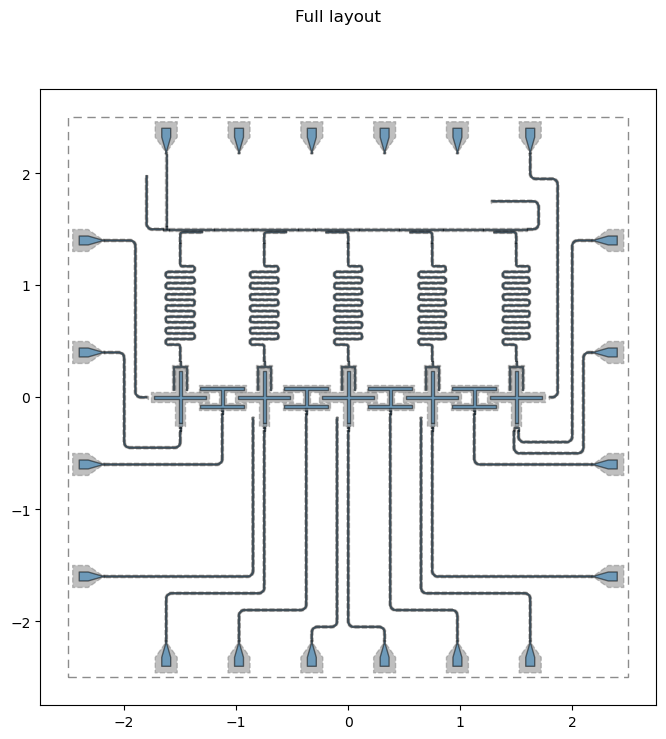

In [51]:
fig = qm.view(design)
fig.suptitle("Full layout")
fig

In [ ]:
# Capacitance check (set run_capacitance_check = True in the parameters).
# Solves the islands' capacitances on the built layout with capacitance.py and
# prints the frequencies the junctions above would give. Paste the C_sigma
# values into the parameters if they differ from the ones assumed there.
if run_capacitance_check:
    from capacitance import capacitance_rows

    mid = n_qubits // 2
    probes = {
        "Q0": (qubit_x(0), qubit_row_y_mm),  # edge qubit: one coupler
        f"Q{mid}": (qubit_x(mid), qubit_row_y_mm),  # inner qubit: two couplers
        f"TC{mid - 1}": ((qubit_x(mid - 1) + qubit_x(mid)) / 2, qubit_row_y_mm),
    }
    rx, ry = design.components[f"Q{mid}"].pins["readout"].middle
    probes["claw"] = (rx, ry + 0.003)
    window = (qubit_x(0) - 0.5, qubit_x(mid) + qubit_pitch_mm * 0.9,
              qubit_row_y_mm - 0.45, qubit_row_y_mm + 0.55)
    rows = capacitance_rows(design, window, probes, pixel_um=1.5)
    for name in ("Q0", f"Q{mid}", f"TC{mid - 1}"):
        c = rows[name][name]
        s = squids[name]
        ec = EC_GHZ_FF / c
        f = (8 * s["ej_ghz"] * ec) ** 0.5 - ec
        print(f"  {name}: C_sigma {c:6.1f} fF, E_C {ec * 1e3:4.0f} MHz -> f_max {f:.2f} GHz"
              f" (target {s['freq_ghz']:.2f})")
    print(f"  qubit-coupler {-rows[f'Q{mid}'][f'TC{mid - 1}']:.2f} fF, "
          f"qubit-claw {-rows[f'Q{mid}']['claw']:.2f} fF")
